# 02 · Preprocesamiento y 320 descriptores

**Jorge Javier Palma Martínez · ML1 FIUNA · 2026**

Protocolo: `deduplicated-v2-2026-11-22`.

Cada vista pasa por escala de grises, ajuste proporcional con padding a 256 × 256 y CLAHE (clip limit 1,5). La regla de ancho ≥500 divide estudios bilaterales por la mitad; es específica del dataset y no detecta anatomía. Se promedian los descriptores de ambas vistas, manteniendo una fila y una etiqueta por estudio.

Vector: 5 estadísticas de intensidad, 3 de gradiente/Laplaciano, 16 bins de histograma, 8 estadísticas por cuadrantes y 288 HOG. El percentil 25 es constante en train por el fondo negro; los descriptores globales incluyen padding. SVD usa además 64 × 64 píxeles. No se imputan radiografías ilegibles: la extracción detiene la ejecución. No se eliminan atípicos por grado o resolución.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/workflow.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src import workflow
# False: show the executed experiment exports; True: recompute this stage.
RECOMPUTE=False


## Ejecutar o consultar la etapa

Los resultados mostrados se cargan de los artefactos calculados por `python scripts/run_pipeline.py`. Para reconstruir, ejecutar los seis notebooks en orden con `RECOMPUTE=True`; para leer la entrega, dejarlo en `False`. Las implementaciones completas están en `src/workflow.py`.

In [2]:
if RECOMPUTE:
    workflow.extract()
import numpy as np
a=np.load(ROOT/'data/processed/features_arrays.npz')
display({k:v.shape for k,v in a.items() if k.startswith('X_')})
display(pd.read_csv(ROOT/'data/processed/features_dataset.csv').iloc[:5,:12])

{'X_train_tabular': (1103, 320),
 'X_train_flat': (1103, 4096),
 'X_val_tabular': (236, 320),
 'X_val_flat': (236, 4096),
 'X_test_tabular': (237, 320),
 'X_test_flat': (237, 4096)}

,path,class_name,class_label,target,width,height,resolution,pixel_sha256,audit_status,split_final,intensity_mean,intensity_std
0,data/raw/Training/0Normal/NormalG0 (16).png,0Normal,Normal,0,300,162,300 x 162,b3844c2572eccdc49de3207ad6f998f6867f3fd59db959...,included,train,71.402970,77.219370
1,data/raw/Training/0Normal/NormalG0 (215).png,0Normal,Normal,0,300,162,300 x 162,5fb27a2870c006dff78cc92c289c40c61cb3a728f35fd6...,included,train,55.530700,75.986010
2,data/raw/Training/0Normal/NormalG0 (485).png,0Normal,Normal,0,640,161,640 x 161,4d8c1bb1b807d22260dc41baf6373bb5c8d2ec7ee2ab1e...,included,train,93.275795,98.082810
3,data/raw/Training/0Normal/NormalG0 (60).png,0Normal,Normal,0,300,162,300 x 162,c41c8f0b7d110855dd586e4d5d15dc9b623dae3f2b14b0...,included,train,68.694000,77.939010
4,data/raw/Training/3Moderate/ModerateG3 (14).png,3Moderate,Moderada,3,300,162,300 x 162,848e24c17999a003a3a3d1872e7ceb50cd478d9ca0ddd4...,included,train,65.911350,77.657295


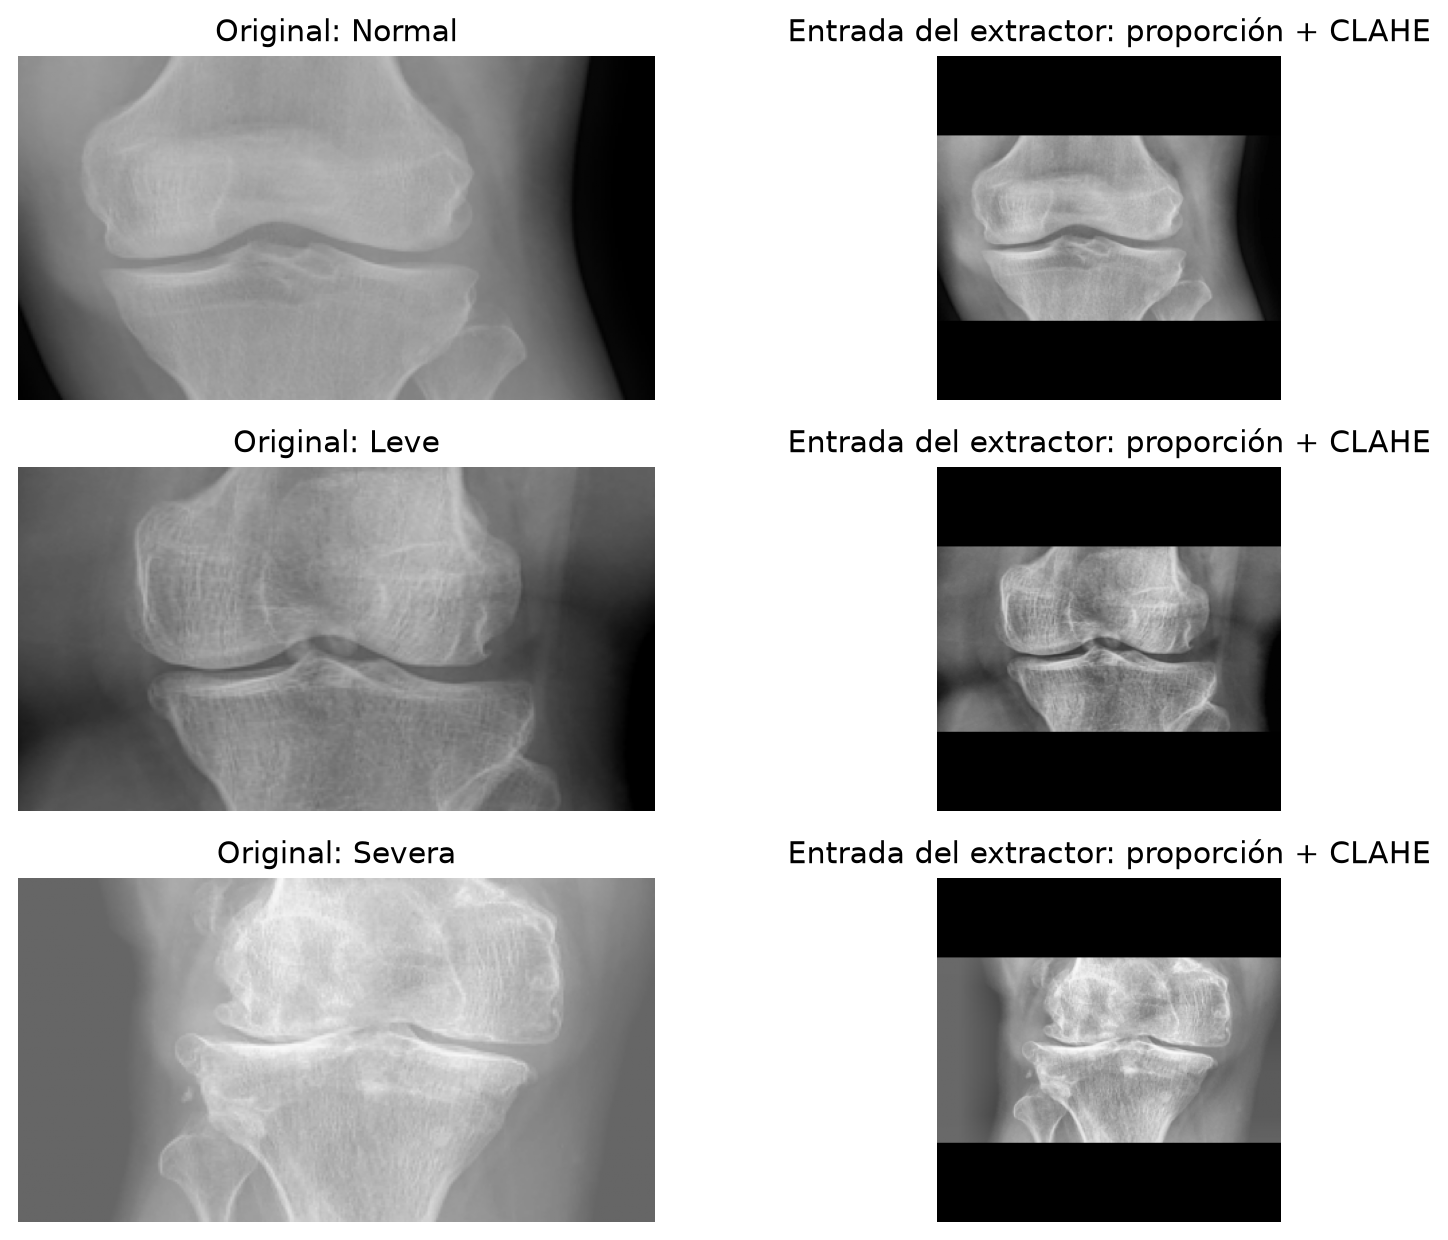

In [3]:
display(Image(filename=str(ROOT/'reports/figures/acondicionamiento_radiografias.png')))